# Monte Carlo Simulation

### Estimate an area

Suppose we want to calculate
\begin{equation*}
I=\int_0^1 x^2\,dx.
\end{equation*}
We know how to calculate this integral analytically:
\begin{equation*}
I=\left[\frac{x^3}{3}\right]_0^1=\frac13.
\end{equation*}

- But suppose we do not know how to integrate the function analytically.
- Can we estimate the integral numerically using random numbers?

### Monte Carlo integration

- Let $U$ be a uniformly distributed random number between 0 and 1.
- Since $U$ is equally likely to fall anywhere in $[0,1]$, the average value of $U^2$ is
  \begin{equation*}
\mathbb E[U^2]=\int_0^1 x^2\,dx.
\end{equation*}

#### This is the central idea: the integral of a function over an interval of length one is the expected value of that function evaluated at a uniformly sampled point.

- We can therefore estimate the integral by generating random points $U_1,\ldots,U_N$, evaluating the function at each point, and calculating the average:

\begin{equation}
\boxed{
I\approx\frac1N\sum_{i=1}^N U_i^2
}
\end{equation}
This is Monte Carlo integration.

More generally, for a continuous function \(f\),
\begin{equation}
\int_a^b f(x)\,dx
=(b-a)\mathbb E[f(U)],
\qquad U\sim\operatorname{Uniform}(a,b).
\end{equation}
Consequently,
\begin{equation}
\boxed{
\int_a^b f(x)\,dx
\approx\frac{b-a}{N}\sum_{i=1}^N f(U_i).
}
\end{equation}

In [1]:
import numpy as np

rng = np.random.default_rng(42)

for N in [10, 100, 1000, 10000, 100000]:
    U = rng.uniform(0, 1, size=N)
    estimate = np.mean(U**2)

    print(f"N = {N:6d}, estimate = {estimate:.6f}")

N =     10, estimate = 0.439233
N =    100, estimate = 0.312546
N =   1000, estimate = 0.335084
N =  10000, estimate = 0.331841
N = 100000, estimate = 0.334315


- Monte Carlo estimates fluctuate, so increasing the sample size improves accuracy in a statistical sense, but does not guarantee that each successive estimate is closer.

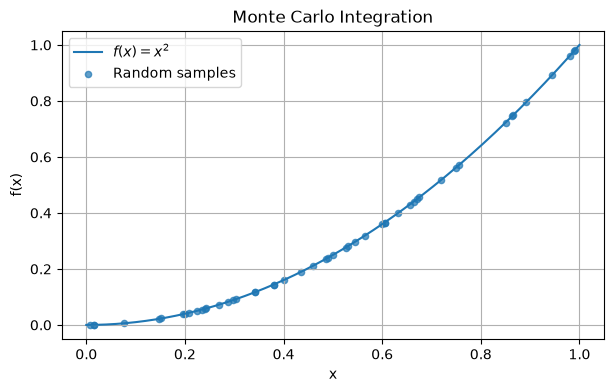

In [2]:
import matplotlib.pyplot as plt

N = 50
U = rng.uniform(0, 1, size=N)
Y = U**2

x = np.linspace(0, 1, 200)

plt.figure(figsize=(7, 4))
plt.plot(x, x**2, label=r"$f(x)=x^2$")
plt.scatter(U, Y, s=20, alpha=0.7,
            label="Random samples")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Monte Carlo Integration")
plt.legend()
plt.grid()
plt.show()

- Each random point gives us a sample of the function value.
- Averaging these values estimates the area under the curve because the sampling is uniform over an interval of length one.

### Watch the estimate converge

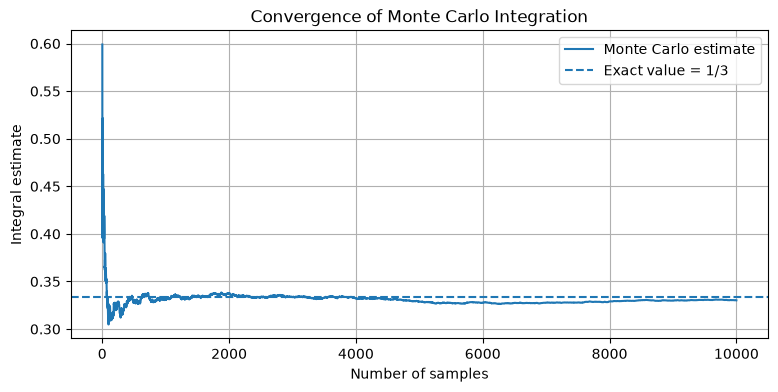

In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

N = 10000
U = rng.uniform(0, 1, size=N)

# Running Monte Carlo estimate
estimates = np.cumsum(U**2) / np.arange(1, N + 1)    # cumulative sum of the elements.

# print(estimates)

plt.figure(figsize=(9, 4))
plt.plot(np.arange(1, N + 1), estimates,
         label="Monte Carlo estimate")

plt.axhline(1/3, linestyle="--",
            label="Exact value = 1/3")

plt.xlabel("Number of samples")
plt.ylabel("Integral estimate")
plt.title("Convergence of Monte Carlo Integration")
plt.legend()
plt.grid()
plt.show()

### How fast does the error decrease?

Define the absolute error by
\begin{equation}
e_N=|I_N-I|,
\end{equation}
where $I=1/3$ is the exact integral.

We know that the error generally decreases as the number of samples increases. But how quickly?

For Monte Carlo integration, the typical error behaves like
\begin{equation}
\boxed{e_N=O(N^{-1/2})}.
\end{equation}
This is the characteristic Monte Carlo convergence rate.

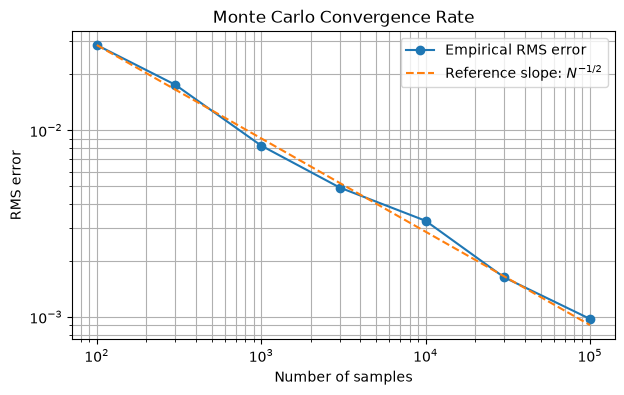

In [9]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

exact = 1/3
sample_sizes = np.array([100, 300, 1000, 3000, 10000, 30000, 100000])
num_trials = 100

rms_errors = []

for N in sample_sizes:
    estimates = []

    for trial in range(num_trials):
        U = rng.uniform(0, 1, size=N)
        estimates.append(np.mean(U**2))

    errors = np.array(estimates) - exact

    rms_errors.append(np.sqrt(np.mean(errors**2)))

rms_errors = np.array(rms_errors)

plt.figure(figsize=(7, 4))
plt.loglog(sample_sizes, rms_errors, "o-",
           label="Empirical RMS error")

plt.loglog(sample_sizes,
           rms_errors[0] * np.sqrt(sample_sizes[0] / sample_sizes),
           "--", label=r"Reference slope: $N^{-1/2}$")

plt.xlabel("Number of samples")
plt.ylabel("RMS error")
plt.title("Monte Carlo Convergence Rate")
plt.legend()
plt.grid(True, which="both")
plt.show()